# Covariance shrinkage and long-only portfolios

This notebook documents CryptoQuantLab's portfolio construction: two Ledoit-Wolf covariance estimates, minimum-variance and risk-parity portfolios, the efficient frontier, how each is computed and checked, and how they did out of sample on the 20 largest coins. They will drive a portfolio page; they are not on the site yet.

The models are [`covariance.ts`](../../backend/src/models/covariance.ts) and [`portfolio.ts`](../../backend/src/models/portfolio.ts). The reference, [`cql_validation/portfolio.py`](../cql_validation/portfolio.py), uses scipy's optimizers rather than the backend's method, and its covariance estimates are checked against scikit-learn and PyPortfolioOpt.

**The main result is that minimum variance cut realized volatility by about 30–40% against a cap-weighted portfolio, but by holding the equivalent of two to five coins, and its most concentrated versions understated their own risk by a quarter or more.** Which covariance estimate it used mattered little on real coins. In simulation, shrinking towards a constant correlation helped and shrinking towards the identity hurt. Optimizing on estimated returns always gave the riskiest portfolio.

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from pypfopt import risk_models
from sklearn.covariance import LedoitWolf

sys.path.insert(0, str(Path.cwd().parent))
from cql_validation import portfolio as pf

plt.rcParams.update({"figure.figsize": (9, 3.4), "figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3})
pd.set_option("display.float_format", lambda x: f"{x:.6g}")

def load(name):
    return np.array(json.loads(Path(f"../../backend/src/test/fixtures/portfolio/{name}.json").read_text())["returns"])

r, wide = load("factor_250x12"), load("wide_40x30")
print(f"simulated two-factor returns: {r.shape[0]} days by {r.shape[1]} assets, and {wide.shape[0]} days by {wide.shape[1]} assets")

simulated two-factor returns: 250 days by 12 assets, and 40 days by 30 assets


\
## 1. Shrinking the covariance

With $p$ assets and $n$ days, the sample covariance estimates $p(p+1)/2$ numbers. When $n$ is not much larger than \
$p$ its extreme eigenvalues are too spread out, and an optimizer leans hardest on exactly the directions that look \
safest by chance. With $n \le p$ it is singular.

Ledoit and Wolf shrink the maximum-likelihood covariance $S$ towards a structured target $F$,

$$\hat\Sigma = \delta F + (1 - \delta) S,$$

with the intensity $\delta$ estimated to minimize expected squared error. Two targets are implemented:

- **Identity** (Ledoit and Wolf, 2004a): $F = \mu I$ with $\mu$ the average variance. It pulls every correlation \
towards zero. This is scikit-learn's `LedoitWolf`.
- **Constant correlation** (Ledoit and Wolf, 2004b): $F_{ii} = s_{ii}$ and $F_{ij} = \bar r \sqrt{s_{ii} s_{jj}}$, \
with $\bar r$ the average sample correlation. It keeps every variance and the common correlation, and only evens out \
the pairwise differences. PyPortfolioOpt implements it, dividing $S$ by $n - 1$ where the authors divide by $n$; the \
check below gives it the authors' convention.

In [2]:
def checks(x):
    identity, identity_shrinkage = pf.ledoit_wolf(x)
    correlated, correlated_shrinkage = pf.constant_correlation(x)
    other = risk_models.CovarianceShrinkage(pd.DataFrame(x), returns_data=True, frequency=1)
    other.S = (x - x.mean(axis=0)).T @ (x - x.mean(axis=0)) / len(x)
    return {
        "identity shrinkage": identity_shrinkage,
        "gap to scikit-learn": np.abs(identity - LedoitWolf().fit(x).covariance_).max() / np.abs(identity).max(),
        "constant-correlation shrinkage": correlated_shrinkage,
        "gap to PyPortfolioOpt": np.abs(correlated - other._ledoit_wolf_constant_correlation()[0]).max() / np.abs(correlated).max(),
        "sample condition number": np.linalg.cond(pf.sample_covariance(x)),
        "identity condition number": np.linalg.cond(identity),
        "constant-correlation condition number": np.linalg.cond(correlated),
    }

pd.DataFrame({"250 days, 12 assets": checks(r), "40 days, 30 assets": checks(wide)})

,"250 days, 12 assets","40 days, 30 assets"
identity shrinkage,0.013245,0.0565973
gap to scikit-learn,0,0
constant-correlation shrinkage,0.170188,0.57225
gap to PyPortfolioOpt,1.22574e-16,2.42416e-16
sample condition number,289.265,7251.34
identity condition number,200.168,339.064
constant-correlation condition number,154.636,304.474


Both estimates match their libraries to rounding. With 30 assets and 40 days the sample covariance is singular, its condition number limited only by rounding, and either shrinkage makes it usable.

Which estimate gives the best portfolio? The next cell draws returns from a known two-factor covariance, like crypto's strong common moves, and measures the true variance of the minimum-variance portfolio built from each estimate, as a percentage above the best possible.

In [3]:
rng = np.random.default_rng(7)
p = 20
loadings = rng.uniform(0.5, 1.5, (2, p))
true_cov = loadings.T @ np.diag([0.03**2, 0.015**2]) @ loadings + np.diag(rng.uniform(0.005, 0.04, p) ** 2)
best = pf.portfolio_variance(pf.minimum_variance(true_cov), true_cov)
chol = np.linalg.cholesky(true_cov)
estimators = {
    "sample": lambda x: pf.sample_covariance(x),
    "identity": lambda x: pf.ledoit_wolf(x)[0],
    "constant correlation": lambda x: pf.constant_correlation(x)[0],
}

rows = {}
for n in (30, 60, 90, 180, 365):
    excess = {name: [] for name in estimators}
    for _ in range(40):
        x = rng.standard_normal((n, p)) @ chol.T
        for name, estimate in estimators.items():
            excess[name].append(pf.portfolio_variance(pf.minimum_variance(estimate(x)), true_cov) / best - 1)
    rows[n] = {f"excess variance, {name}": np.mean(v) for name, v in excess.items()}
pd.DataFrame(rows).T.rename_axis(f"days ({p} assets)").map(lambda v: f"{v:.1%}")

,"excess variance, sample","excess variance, identity","excess variance, constant correlation"
days (20 assets),,,
30,6.8%,13.3%,3.3%
60,4.1%,7.2%,2.1%
90,2.5%,3.6%,1.3%
180,1.4%,1.9%,0.7%
365,0.4%,0.5%,0.3%


**Shrinking towards the identity made the portfolio worse than no shrinkage at every window length**, and shrinking towards a constant correlation roughly halved the sample covariance's excess. With strongly correlated assets, the identity target pulls correlations towards zero, so the optimizer sees diversification that isn't there. The long-only constraint already does part of the regularizing (Jagannathan and Ma, 2003), which is why the sample covariance does reasonably well on its own.

## 2. Long-only portfolios

All portfolios here are fully invested and long-only: $w \ge 0$, $\sum_i w_i = 1$.

- **Minimum variance** minimizes $w' \Sigma w$. At the optimum every held asset has the same marginal variance $(\Sigma w)_i$, and every asset left out has at least as much. The backend uses the primal active-set method (Nocedal and Wright, Algorithm 16.3), and the tests check those conditions to 1e-12.
- **Risk parity** gives each asset an equal share of variance, $w_i (\Sigma w)_i = w'\Sigma w / n$. Spinu (2013) shows this is the minimizer of the convex $\tfrac12 y'\Sigma y - \tfrac1n \sum_i \log y_i$ after scaling $y$ to sum to 1, so Newton's method finds it reliably.
- **The efficient frontier** is the minimum variance at each target return. The backend finds each point by minimizing $\tfrac12 w'\Sigma w - t\, \mu' w$ and bisecting on $t$, since the portfolio's return rises continuously with $t$.

The reference instead runs scipy's SLSQP, then solves the optimality conditions exactly on the assets SLSQP holds and checks them, so the two implementations agree only if both find the true optimum.

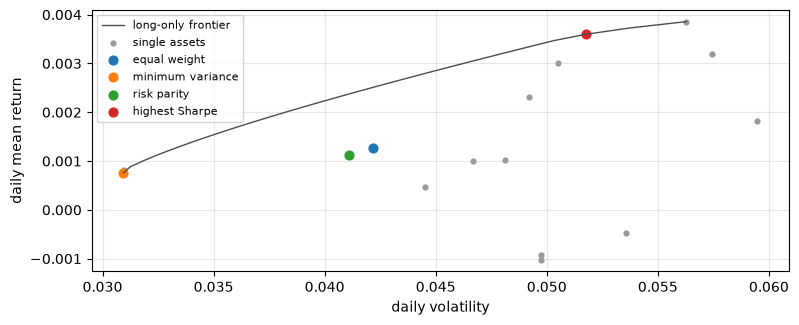

,assets held,largest weight,largest risk share,smallest risk share
equal weight,12,0.0833333,0.0990026,0.0553454
minimum variance,3,0.954016,0.954016,0
risk parity,12,0.121856,0.0833333,0.0833333
highest Sharpe,3,0.675549,0.720478,0


In [4]:
cov = pf.constant_correlation(r)[0]
mean = r.mean(axis=0)
frontier = pf.efficient_frontier(cov, mean, 25)
marked = {
    "equal weight": np.full(len(mean), 1 / len(mean)),
    "minimum variance": pf.minimum_variance(cov),
    "risk parity": pf.risk_parity(cov),
    "highest Sharpe": max(frontier, key=lambda w: (w @ mean) / np.sqrt(w @ cov @ w)),
}
fig, ax = plt.subplots()
ax.plot([np.sqrt(w @ cov @ w) for w in frontier], [w @ mean for w in frontier], color="0.3", lw=1, label="long-only frontier")
ax.scatter(np.sqrt(np.diag(cov)), mean, s=12, color="0.6", label="single assets")
for name, w in marked.items():
    ax.scatter(np.sqrt(w @ cov @ w), w @ mean, s=40, label=name)
ax.set_xlabel("daily volatility")
ax.set_ylabel("daily mean return")
ax.legend(fontsize=8)
plt.show()

pd.DataFrame({
    name: {"assets held": int((w > 1e-12).sum()), "largest weight": w.max(), "largest risk share": pf.risk_contributions(w, cov).max(), "smallest risk share": pf.risk_contributions(w, cov).min()}
    for name, w in marked.items()
}).T

Minimum variance holds a few assets and gives them very unequal shares of risk. Risk parity holds everything with equal risk shares. The highest-Sharpe point depends entirely on the estimated means, which is the problem the backtest shows.

## 3. Out of sample on the 20 largest coins

[`scripts/portfolio_backtest.py`](../scripts/portfolio_backtest.py) rebalances every 30 days. At each rebalance it takes the 20 largest coins by market cap whose daily volatility over the estimation window is at least 0.5%, which removes stablecoins and tokenized funds, sets each strategy's weights from that window, and holds without trading until the next rebalance. Minimum variance runs on each of the three covariance estimates; risk parity, the highest-Sharpe portfolio and the risk forecasts of the simple weightings use constant-correlation shrinkage. Every combination of a 90 or 180-day window and three starting offsets covers the same test days, from late April to early November 2026.

In [5]:
summary = pd.read_csv("../data/portfolio_backtest_summary.csv")
periods = pd.read_csv("../data/portfolio_backtest_periods.csv")
names = {
    "cap_weight": "cap-weighted", "equal_weight": "equal weight", "inverse_volatility": "inverse volatility",
    "min_variance_sample": "minimum variance, sample", "min_variance_identity": "minimum variance, identity",
    "min_variance_constant_correlation": "minimum variance, constant correlation",
    "risk_parity": "risk parity", "max_sharpe": "highest Sharpe",
}
columns = {
    "annualized_volatility": "annualized volatility", "max_drawdown": "max drawdown", "total_return": "return",
    "mean_turnover": "turnover per rebalance", "mean_effective_holdings": "effective holdings",
    "realized_over_forecast_volatility": "realized / forecast volatility",
}

def table(universe):
    frame = summary[summary.universe == universe].groupby("strategy")[list(columns)].mean()
    largest = periods[periods.universe == universe].groupby("strategy").largest_weight.mean().rename("largest weight")
    return frame.join(largest).rename(index=names, columns=columns).sort_values("annualized volatility")

print(f"{summary.days.iloc[0]} test days; averages over 6 schedules")
print(periods.groupby("window")[["identity_shrinkage", "constant_correlation_shrinkage"]].mean().rename_axis("window, mean shrinkage"))
table("top_20")

197 test days; averages over 6 schedules
                        identity_shrinkage  constant_correlation_shrinkage
window, mean shrinkage                                                    
90                                0.147514                         0.30066
180                              0.0782225                         0.15669


,annualized volatility,max drawdown,return,turnover per rebalance,effective holdings,realized / forecast volatility,largest weight
strategy,,,,,,,
"minimum variance, identity",0.216702,0.16691,-0.0469972,0.167135,3.57023,0.984928,0.44889
"minimum variance, sample",0.21764,0.183217,-0.0693559,0.14827,2.09392,1.30793,0.640747
"minimum variance, constant correlation",0.219256,0.176037,-0.0608407,0.153277,1.9304,1.24962,0.675245
risk parity,0.344681,0.20365,-0.00379605,0.115361,13.5106,0.96272,0.170727
inverse volatility,0.375381,0.227369,0.0121368,0.110401,16.1562,0.970897,0.127586
cap-weighted,0.381487,0.28138,-0.00464228,0.00347037,1.95808,0.902238,0.700829
equal weight,0.445997,0.245977,0.0331605,0.104267,20,0.989338,0.05
highest Sharpe,0.512794,0.301655,0.0168922,0.503073,3.1652,0.958482,0.478889


Averaged over the six schedules:

- **Minimum variance had the lowest volatility by far,** about 22% a year against 38% for cap-weighted and 45% for equal weight, and the smallest drawdown, whichever covariance it used. It did so by holding the equivalent of two to four coins.
- **Concentrated portfolios understated their own risk.** On the sample and constant-correlation estimates, minimum variance's realized volatility was 25–31% above its own forecast. The identity estimate spread the weights more and forecast its risk accurately.
- **The highest-Sharpe portfolio was the riskiest,** with the deepest drawdown and about half the portfolio traded each month.
- **Risk parity sat in between,** below every simple weighting on volatility while holding all 20 coins.

Returns are shown for completeness: over six months, they say almost nothing about which strategy is better.

### Is it one coin?

Minimum variance put most of the portfolio into TRON, the least volatile large coin over the period. The same backtest without TRON:

In [6]:
table("top_20_without_tron")

,annualized volatility,max drawdown,return,turnover per rebalance,effective holdings,realized / forecast volatility,largest weight
strategy,,,,,,,
"minimum variance, constant correlation",0.2601,0.203173,-0.0672908,0.242294,3.06304,0.920927,0.536457
"minimum variance, sample",0.264507,0.204915,-0.0741655,0.245501,3.21863,0.983481,0.519906
"minimum variance, identity",0.280621,0.218949,-0.0678693,0.236359,4.70894,0.952869,0.386589
cap-weighted,0.386472,0.28427,-0.00508513,0.0040386,1.9062,0.901279,0.710482
risk parity,0.39701,0.235926,-0.0297604,0.132507,15.8868,0.986477,0.142587
inverse volatility,0.419833,0.25452,-0.012352,0.126166,17.6454,0.993363,0.0974427
equal weight,0.465089,0.262104,0.00734952,0.118036,20,0.994048,0.05
highest Sharpe,0.626656,0.329513,0.0920319,0.496509,3.32881,0.947512,0.441544


Without TRON, minimum variance still has the lowest volatility, 26–28% against 39% for cap-weighted, so the result isn't one coin. The covariance estimates now separate a little, in the order the simulation predicts: constant correlation lowest and identity highest, about two percentage points apart. Risk parity is now slightly above cap-weighted, though still below equal weight and inverse volatility. The highest-Sharpe portfolio had the best return here and a middling one with TRON, which is what noise looks like.

The schedules agree closely, so these averages aren't one lucky start date:

In [7]:
grid = summary.pivot_table(index=["universe", "strategy"], columns=["window", "offset"], values="annualized_volatility")
grid.rename(index=names).map(lambda v: f"{v:.1%}")

window                                                        90          \
offset                                                         0      10   
universe            strategy                                               
top_20              cap-weighted                            37.5%  38.1%   
                    equal weight                            44.5%  43.8%   
                    inverse volatility                      36.9%  36.5%   
                    highest Sharpe                          55.4%  49.7%   
                    minimum variance, constant correlation  21.8%  23.1%   
                    minimum variance, identity              21.8%  22.3%   
                    minimum variance, sample                21.5%  22.6%   
                    risk parity                             33.9%  33.4%   
top_20_without_tron cap-weighted                            38.0%  38.6%   
                    equal weight                            46.4%  45.6%   
                    inverse volatility                      41.2%  40.9%   
                    highest Sharpe                          63.3%  59.4%   
                    minimum variance, constant correlation  23.2%  25.4%   
                    minimum variance, identity              26.5%  28.2%   
                    minimum variance, sample                23.8%  26.4%   
                    risk parity                             38.8%  38.3%   

window                                                               180  \
offset                                                         20     0    
universe            strategy                                               
top_20              cap-weighted                            38.8%  37.5%   
                    equal weight                            45.5%  44.5%   
                    inverse volatility                      37.3%  38.0%   
                    highest Sharpe                          54.9%  53.7%   
                    minimum variance, constant correlation  22.1%  21.2%   
                    minimum variance, identity              21.1%  21.2%   
                    minimum variance, sample                21.7%  21.3%   
                    risk parity                             34.0%  35.0%   
top_20_without_tron cap-weighted                            39.3%  38.0%   
                    equal weight                            47.4%  46.6%   
                    inverse volatility                      41.7%  42.5%   
                    highest Sharpe                          64.6%  62.5%   
                    minimum variance, constant correlation  22.5%  27.4%   
                    minimum variance, identity              25.4%  29.0%   
                    minimum variance, sample                22.8%  27.7%   
                    risk parity                             38.9%  40.7%   

window                                                                    
offset                                                         10     20  
universe            strategy                                              
top_20              cap-weighted                            38.1%  38.8%  
                    equal weight                            43.8%  45.5%  
                    inverse volatility                      37.8%  38.8%  
                    highest Sharpe                          46.8%  47.3%  
                    minimum variance, constant correlation  21.5%  21.9%  
                    minimum variance, identity              21.6%  22.0%  
                    minimum variance, sample                21.5%  22.0%  
                    risk parity                             34.9%  35.6%  
top_20_without_tron cap-weighted                            38.6%  39.3%  
                    equal weight                            45.7%  47.4%  
                    inverse volatility                      42.3%  43.3%  
                    highest Sharpe                          

## 4. What this means for the portfolio page

- **Use constant-correlation shrinkage.** It was best in simulation, about as good as the others on real coins and best without TRON, and it works when a user holds more coins than there are days of shared history. The identity target, the common default, is the wrong one for assets that move together this much.
- **Cap the weights.** Minimum variance's lower risk is real here, but it comes from very few holdings, and those portfolios underestimated their risk. A maximum weight per coin is the usual fix and isn't implemented yet. Until then, the page should show weights and each coin's share of risk next to the volatility.
- **Don't recommend the highest-Sharpe portfolio.** Show the frontier as what the past year's averages imply, not as advice.
- **Risk parity is the diversified option,** holding every coin with less risk than equal weight or inverse volatility, and about the same as cap-weighted.

## 5. Limitations

- **Survivorship.** The coins come from today's top 100, so coins that fell out of the top 20 and then out of the top 100 are missing from earlier rebalances.
- **A short test.** About six months and seven rebalances, with no transaction costs; turnover is reported instead.
- **Long-only and fully invested.** No cash, no leverage and no shorting, which matches what most holders can do.
- **Daily closes at 00:00 UTC.** Correlations from daily closes understate how assets that trade around the clock move together within a day.

## References

- DeMiguel, V., Garlappi, L. and Uppal, R. (2009). Optimal versus naive diversification: how inefficient is the 1/N portfolio strategy? *Review of Financial Studies*, 22(5), 1915–1953.
- Jagannathan, R. and Ma, T. (2003). Risk reduction in large portfolios: why imposing the wrong constraints helps. *Journal of Finance*, 58(4), 1651–1683.
- Ledoit, O. and Wolf, M. (2004a). A well-conditioned estimator for large-dimensional covariance matrices. *Journal of Multivariate Analysis*, 88(2), 365–411.
- Ledoit, O. and Wolf, M. (2004b). Honey, I shrunk the sample covariance matrix. *Journal of Portfolio Management*, 30(4), 110–119.
- Martin, R. A. (2021). PyPortfolioOpt: portfolio optimization in Python. *Journal of Open Source Software*, 6(61), 3066.
- Maillard, S., Roncalli, T. and Teïletche, J. (2010). The properties of equally weighted risk contribution portfolios. *Journal of Portfolio Management*, 36(4), 60–70.
- Markowitz, H. (1952). Portfolio selection. *Journal of Finance*, 7(1), 77–91.
- Nocedal, J. and Wright, S. J. (2006). *Numerical Optimization*, 2nd edition. Springer.
- Pedregosa, F. et al. (2011). Scikit-learn: machine learning in Python. *Journal of Machine Learning Research*, 12, 2825–2830.
- Spinu, F. (2013). An algorithm for computing risk parity weights. SSRN 2297383.